# **Predicting Problematic Internet Usage Based on Physical Activity**

# **Introduction**


In today's digital age, the internet has become an essential part of our lives, offering countless benefits for learning, entertainment, and communication. However, excessive use, especially among children and adolescents, has given rise to a growing concern: problematic internet usage. This can manifest in negative behaviors such as compulsivity, dependency, and escapism, often linked to mental health challenges like anxiety, depression, and social withdrawal.

Current methods for identifying problematic internet use rely on professional assessments, which can be complex, costly, and inaccessible for many families. These barriers highlight the urgent need for innovative, scalable solutions that can address this issue effectively.

This project seeks to bridge this gap by using physical fitness and activity data—simple, widely available indicators—as a proxy to predict early signs of problematic internet use. By leveraging machine learning and data-driven insights, we aim to build a predictive model that identifies at-risk individuals, enabling timely interventions to encourage healthier digital habits and promote overall well-being.

This work isn’t just about building a model; it’s about making a meaningful impact on the mental health and quality of life for future generations.

# **Problem Statement**

Problematic internet use among children and adolescents is a growing issue, with far-reaching implications for their mental and physical well-being. Excessive screen time and technology dependency have been linked to a range of negative outcomes, including poor posture, irregular diets, reduced physical activity, and mental health challenges such as anxiety and depression.

Despite its seriousness, identifying problematic internet use early remains a challenge. Current methods rely heavily on professional assessments, which are often complex, costly, and inaccessible to many families due to cultural, linguistic, and logistical barriers. As a result, early intervention opportunities are often missed, leaving children and their families without the support they need.

On the other hand, physical activity and fitness data, such as movement patterns, sleep quality, and cardiovascular health, are widely available and easy to collect. These metrics could provide valuable insights into behavioral changes associated with excessive internet use, offering a practical, non-invasive alternative for early detection.

This project seeks to address the gap by using physical activity and fitness indicators to develop a predictive model for identifying problematic internet use. By leveraging accessible data, we aim to enable proactive interventions, promoting healthier digital habits and supporting the mental and physical health of children and adolescents.

# **Dataset Overview**


* Healthy Brain Network (HBN) Dataset
    * Participants: 5,000 children and adolescents (5-22 years old).
    * Data Types:
          * Tabular: Demographics, physical measures, fitness tests, internet usage behavior.
          * Time-series: Accelerometer data from wrist-worn devices.
    * Target: Severity Impairment Index (sii) - None (0), Mild (1), Moderate (2), Severe (3).
* Key Features:
    * ENMO (activity measure), sleep disturbances, BMI, internet usage hours.


# Load the Data

In [1]:
# Importing necessary libraries
import pandas as pd
import pyarrow.parquet as pq
# Importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# For machine learning models
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import cohen_kappa_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, Flatten

# For time-series processing
import pyarrow.parquet as pq
from tsfresh import extract_features

# For evaluation metric (Quadratic Weighted Kappa)
from sklearn.metrics import make_scorer

# Load CSV files
train_data = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/train.csv')
test_data = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/test.csv')
data_dictionary = pd.read_csv('/kaggle/input/child-mind-institute-problematic-internet-use/data_dictionary.csv')

In [2]:
# Display the head of each dataset
train_data.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
test_data.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,BIA-BIA_TBW,PAQ_A-Season,PAQ_A-PAQ_A_Total,PAQ_C-Season,PAQ_C-PAQ_C_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,32.6909,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,3.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,27.0552,NaN,NaN,Fall,2.340,Fall,46.0,64.0,Summer,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,NaN,NaN,NaN,Summer,2.170,Fall,38.0,54.0,Summer,2.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,45.9966,NaN,NaN,Winter,2.451,Summer,31.0,45.0,Winter,0.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,...,NaN,Summer,1.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
data_dictionary.head()

,Instrument,Field,Description,Type,Values,Value Labels
0,Identifier,id,Participant's ID,str,NaN,NaN
1,Demographics,Basic_Demos-Enroll_Season,Season of enrollment,str,"Spring, Summer, Fall, Winter",NaN
2,Demographics,Basic_Demos-Age,Age of participant,float,NaN,NaN
3,Demographics,Basic_Demos-Sex,Sex of participant,categorical int,"0,1","0=Male, 1=Female"
4,Children's Global Assessment Scale,CGAS-Season,Season of participation,str,"Spring, Summer, Fall, Winter",NaN


In [5]:
# Load Parquet files for time-series data
# Example for a single file, assuming the directory structure is consistent
import glob

# Directory paths for time-series data
train_parquet_files = glob.glob('/kaggle/input/child-mind-institute-problematic-internet-use/series_train.parquet/*')
test_parquet_files = glob.glob('/kaggle/input/child-mind-institute-problematic-internet-use/series_test.parquet/*')

# Load a sample Parquet file to understand its structure
sample_parquet = pq.read_table(train_parquet_files[0]).to_pandas()

print("\nSample Parquet Data:")
print(sample_parquet.head())

# Save all Parquet file paths for further processing
train_parquet_dict = {file.split('=')[-1]: file for file in train_parquet_files}
test_parquet_dict = {file.split('=')[-1]: file for file in test_parquet_files}

# Check number of Parquet files loaded
print(f"\nNumber of train Parquet files: {len(train_parquet_dict)}")
print(f"Number of test Parquet files: {len(test_parquet_dict)}")


Sample Parquet Data:
   step         X         Y         Z      enmo     anglez  non-wear_flag  \
0     0  0.088385 -0.021719  0.988333  0.000192  84.628494            0.0   
1     1  0.088750 -0.021823  0.988698  0.000246  84.657318            0.0   
2     2  0.022700 -0.015929  0.988151  0.023109  87.189415            0.0   
3     3 -0.076641 -0.048411  0.932135  0.043126  85.428131            0.0   
4     4  0.006432  0.036354  1.000651  0.006071  88.175079            0.0   

       light  battery_voltage     time_of_day  weekday  quarter  \
0   8.250000      4186.000000  52200000000000        6        2   
1  15.666667      4185.166504  52205000000000        6        2   
2  13.583333      4187.000000  54385000000000        6        2   
3  11.500000      4187.000000  54390000000000        6        2   
4   1.661765      4187.000000  54395000000000        6        2   

   relative_date_PCIAT  
0                 15.0  
1                 15.0  
2                 15.0  
3           

## Data Preprocessing

In [6]:
pseudo_train = train_data.copy()
pseudo_train = pseudo_train.dropna(subset=['sii'])
pseudo_train.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
5,001f3379,Spring,13,1,Winter,50.0,Summer,22.279952,59.5,112.2,...,1.0,2.0,1.0,34.0,Summer,40.0,56.0,Spring,0.0,1.0


In [7]:
pseudo_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2736 entries, 0 to 3958
Data columns (total 82 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   id                                      2736 non-null   object 
 1   Basic_Demos-Enroll_Season               2736 non-null   object 
 2   Basic_Demos-Age                         2736 non-null   int64  
 3   Basic_Demos-Sex                         2736 non-null   int64  
 4   CGAS-Season                             2342 non-null   object 
 5   CGAS-CGAS_Score                         2342 non-null   float64
 6   Physical-Season                         2595 non-null   object 
 7   Physical-BMI                            2527 non-null   float64
 8   Physical-Height                         2530 non-null   float64
 9   Physical-Weight                         2572 non-null   float64
 10  Physical-Waist_Circumference            483 non-null    float64
 

In [8]:
criterio = 0.4 * len(train_data)
columnas = pseudo_train.columns[pseudo_train.isnull().sum() < criterio]

pseudo_train = pseudo_train[columnas]
pseudo_train = pseudo_train.fillna(0)

pseudo_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2736 entries, 0 to 3958
Data columns (total 72 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   id                                      2736 non-null   object 
 1   Basic_Demos-Enroll_Season               2736 non-null   object 
 2   Basic_Demos-Age                         2736 non-null   int64  
 3   Basic_Demos-Sex                         2736 non-null   int64  
 4   CGAS-Season                             2736 non-null   object 
 5   CGAS-CGAS_Score                         2736 non-null   float64
 6   Physical-Season                         2736 non-null   object 
 7   Physical-BMI                            2736 non-null   float64
 8   Physical-Height                         2736 non-null   float64
 9   Physical-Weight                         2736 non-null   float64
 10  Physical-Diastolic_BP                   2736 non-null   float64
 

In [9]:
tabla_cuali = ['Basic_Demos-Enroll_Season', 'CGAS-Season', 
               'Physical-Season', 'Fitness_Endurance-Season', 
               'FGC-Season','BIA-Season',
               'PAQ_C-Season', 'PCIAT-Season',
               'SDS-Season', 'PreInt_EduHx-Season']
columnas_num = ['Basic_Demos-Age', 'Basic_Demos-Sex', 'CGAS-CGAS_Score', 
                'Physical-BMI', 'Physical-Height', 'Physical-Weight',
               'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP', 
                'PCIAT-PCIAT_01',
                'PCIAT-PCIAT_02', 'PCIAT-PCIAT_03', 'PCIAT-PCIAT_04', 'PCIAT-PCIAT_05',
                'PCIAT-PCIAT_06', 'PCIAT-PCIAT_07', 'PCIAT-PCIAT_08', 'PCIAT-PCIAT_09',
                'PCIAT-PCIAT_10', 'PCIAT-PCIAT_11', 'PCIAT-PCIAT_12', 'PCIAT-PCIAT_13',
                'PCIAT-PCIAT_14', 'PCIAT-PCIAT_15', 'PCIAT-PCIAT_16', 'PCIAT-PCIAT_17',
                'PCIAT-PCIAT_18', 'PCIAT-PCIAT_19', 'PCIAT-PCIAT_20', 'PCIAT-PCIAT_Total',
                'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T',
       'PreInt_EduHx-computerinternet_hoursday', 'sii', 'id']


# Tabular Data Preprocessing

In [10]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Identify numeric and categorical columns
numeric_cols = train_data.select_dtypes(include=['float64', 'int64']).columns
categorical_cols = train_data.select_dtypes(include=['object']).columns

# Check for missing columns between train and test data
missing_cols = set(train_data.columns) - set(test_data.columns)

# Handle missing columns in test data (add them with default values if necessary)
for col in missing_cols:
    if col in numeric_cols:
        test_data[col] = 0  # Filling numeric columns with 0
    elif col in categorical_cols:
        test_data[col] = "Unknown"  # Filling categorical columns with "Unknown"

# Initialize imputer for numeric columns (using mean for imputation)
numeric_imputer = SimpleImputer(strategy='mean')

# Impute missing values in numeric columns for both train and test data
train_data[numeric_cols] = numeric_imputer.fit_transform(train_data[numeric_cols])
test_data[numeric_cols] = numeric_imputer.transform(test_data[numeric_cols])

# Initialize imputer for categorical columns (using most frequent value for imputation)
categorical_imputer = SimpleImputer(strategy='most_frequent')

# Impute missing values in categorical columns for both train and test data
train_data[categorical_cols] = categorical_imputer.fit_transform(train_data[categorical_cols])
test_data[categorical_cols] = categorical_imputer.transform(test_data[categorical_cols])

# Verify if all missing values are handled
print(f"Missing values in train data after preprocessing: {train_data.isnull().sum()}")
print(f"Missing values in test data after preprocessing: {test_data.isnull().sum()}")


Missing values in train data after preprocessing: id                                        0
Basic_Demos-Enroll_Season                 0
Basic_Demos-Age                           0
Basic_Demos-Sex                           0
CGAS-Season                               0
                                         ..
SDS-SDS_Total_Raw                         0
SDS-SDS_Total_T                           0
PreInt_EduHx-Season                       0
PreInt_EduHx-computerinternet_hoursday    0
sii                                       0
Length: 82, dtype: int64
Missing values in test data after preprocessing: id                           0
Basic_Demos-Enroll_Season    0
Basic_Demos-Age              0
Basic_Demos-Sex              0
CGAS-Season                  0
                            ..
PCIAT-PCIAT_19               0
PCIAT-PCIAT_02               0
PCIAT-Season                 0
PCIAT-PCIAT_Total            0
PCIAT-PCIAT_17               0
Length: 82, dtype: int64


# Time-Series Data Preprocessing

In [11]:
# Step 3b: Time-Series Data Preprocessing

# Aggregating features from time-series data
def process_parquet(file_path):
    # Load Parquet file
    df = pq.read_table(file_path).to_pandas()

    # Handle missing values in time-series data
    df.fillna(0, inplace=True)

    # Generate features: Mean, Std, Min, Max for each numeric column
    feature_dict = {}
    feature_dict['id'] = file_path.split('=')[-1]  # Extract ID from file path
    for col in ['X', 'Y', 'Z', 'enmo', 'anglez', 'light', 'battery_voltage']:
        feature_dict[f'{col}_mean'] = df[col].mean()
        feature_dict[f'{col}_std'] = df[col].std()
        feature_dict[f'{col}_min'] = df[col].min()
        feature_dict[f'{col}_max'] = df[col].max()

    return feature_dict

# Process all Parquet files
train_time_features = pd.DataFrame([process_parquet(file) for file in train_parquet_files])
test_time_features = pd.DataFrame([process_parquet(file) for file in test_parquet_files])

print("\nTime-series features from train data:")
print(train_time_features.head())



Time-series features from train data:
         id    X_mean     X_std     X_min     X_max    Y_mean     Y_std  \
0  0745c390 -0.054638  0.633126 -1.812031  1.850391 -0.163923  0.513286   
1  eaab7a96  0.113277  0.507897 -1.807955  1.928769  0.093139  0.541129   
2  8ec2cc63 -0.499738  0.454021 -1.903281  1.021510  0.046381  0.510668   
3  b2987a65  0.007430  0.586100 -1.684624  5.908000  0.007583  0.542189   
4  7b8842c3  0.086653  0.509845 -1.675859  3.231563 -0.115162  0.494897   

      Y_min     Y_max    Z_mean  ...  anglez_min  anglez_max  light_mean  \
0 -2.631380  3.580182 -0.114302  ...  -89.987045   89.422226   46.009533   
1 -2.887664  3.234613 -0.106038  ...  -89.654587   89.080330   56.437958   
2 -3.150104  1.016589 -0.181152  ...  -89.540176   86.987267   77.305130   
3 -2.405738  2.083693 -0.196510  ...  -89.968369   89.976074    9.369678   
4 -1.071042  1.033620 -0.138969  ...  -89.770241   89.300034    5.049157   

    light_std  light_min    light_max  battery_voltag

# Combining Tabular and Time-Series Data

In [12]:
# Step 3c: Merge Tabular and Time-Series Features

# Ensure 'id' columns are treated as strings
train_time_features['id'] = train_time_features['id'].astype(str)
test_time_features['id'] = test_time_features['id'].astype(str)

# Merge time-series features with tabular data
merged_train_data = pd.merge(train_data, train_time_features, on='id', how='left')
merged_test_data = pd.merge(test_data, test_time_features, on='id', how='left')

print("\nFinal Train Data after merging:")
print(train_data.head())


Final Train Data after merging:
         id Basic_Demos-Enroll_Season  Basic_Demos-Age  Basic_Demos-Sex  \
0  00008ff9                      Fall              5.0              0.0   
1  000fd460                    Summer              9.0              0.0   
2  00105258                    Summer             10.0              1.0   
3  00115b9f                    Winter              9.0              0.0   
4  0016bb22                    Spring             18.0              1.0   

  CGAS-Season  CGAS-CGAS_Score Physical-Season  Physical-BMI  Physical-Height  \
0      Winter        51.000000            Fall     16.877316        46.000000   
1      Spring        65.454771            Fall     14.035590        48.000000   
2        Fall        71.000000            Fall     16.648696        56.500000   
3        Fall        71.000000          Summer     18.292347        56.000000   
4      Summer        65.454771          Spring     19.331929        55.946713   

   Physical-Weight  ...  PCIA

# Exploratory Data Analysis (EDA)

1. Overview of the Dataset

In [13]:
# Display first few rows of the training and test data
print("Train Data Overview:")
print(merged_train_data.head())

print("Test Data Overview:")
print(merged_test_data.head())

# Summary statistics for numerical columns
print("Train Data Summary Statistics:")
print(merged_train_data.describe())

print("Test Data Summary Statistics:")
print(merged_test_data.describe())


Train Data Overview:
         id Basic_Demos-Enroll_Season  Basic_Demos-Age  Basic_Demos-Sex  \
0  00008ff9                      Fall              5.0              0.0   
1  000fd460                    Summer              9.0              0.0   
2  00105258                    Summer             10.0              1.0   
3  00115b9f                    Winter              9.0              0.0   
4  0016bb22                    Spring             18.0              1.0   

  CGAS-Season  CGAS-CGAS_Score Physical-Season  Physical-BMI  Physical-Height  \
0      Winter        51.000000            Fall     16.877316        46.000000   
1      Spring        65.454771            Fall     14.035590        48.000000   
2        Fall        71.000000            Fall     16.648696        56.500000   
3        Fall        71.000000          Summer     18.292347        56.000000   
4      Summer        65.454771          Spring     19.331929        55.946713   

   Physical-Weight  ...  anglez_min  angl

2. Check for Missing Values

In [14]:
# Missing values in the train and test datasets
print("Missing Values in Train Data:")
print(merged_train_data.isnull().sum())

print("Missing Values in Test Data:")
print(merged_test_data.isnull().sum())

# Percentage of missing values
print("Missing Values Percentage in Train Data:")
print(merged_train_data.isnull().mean() * 100)

print("Missing Values Percentage in Test Data:")
print(merged_test_data.isnull().mean() * 100)


Missing Values in Train Data:
id                              0
Basic_Demos-Enroll_Season       0
Basic_Demos-Age                 0
Basic_Demos-Sex                 0
CGAS-Season                     0
                             ... 
light_max                    2964
battery_voltage_mean         2964
battery_voltage_std          2964
battery_voltage_min          2964
battery_voltage_max          2964
Length: 110, dtype: int64
Missing Values in Test Data:
id                            0
Basic_Demos-Enroll_Season     0
Basic_Demos-Age               0
Basic_Demos-Sex               0
CGAS-Season                   0
                             ..
light_max                    18
battery_voltage_mean         18
battery_voltage_std          18
battery_voltage_min          18
battery_voltage_max          18
Length: 110, dtype: int64
Missing Values Percentage in Train Data:
id                            0.000000
Basic_Demos-Enroll_Season     0.000000
Basic_Demos-Age               0.000000
Basic

3. Data Distribution (Numerical Features)

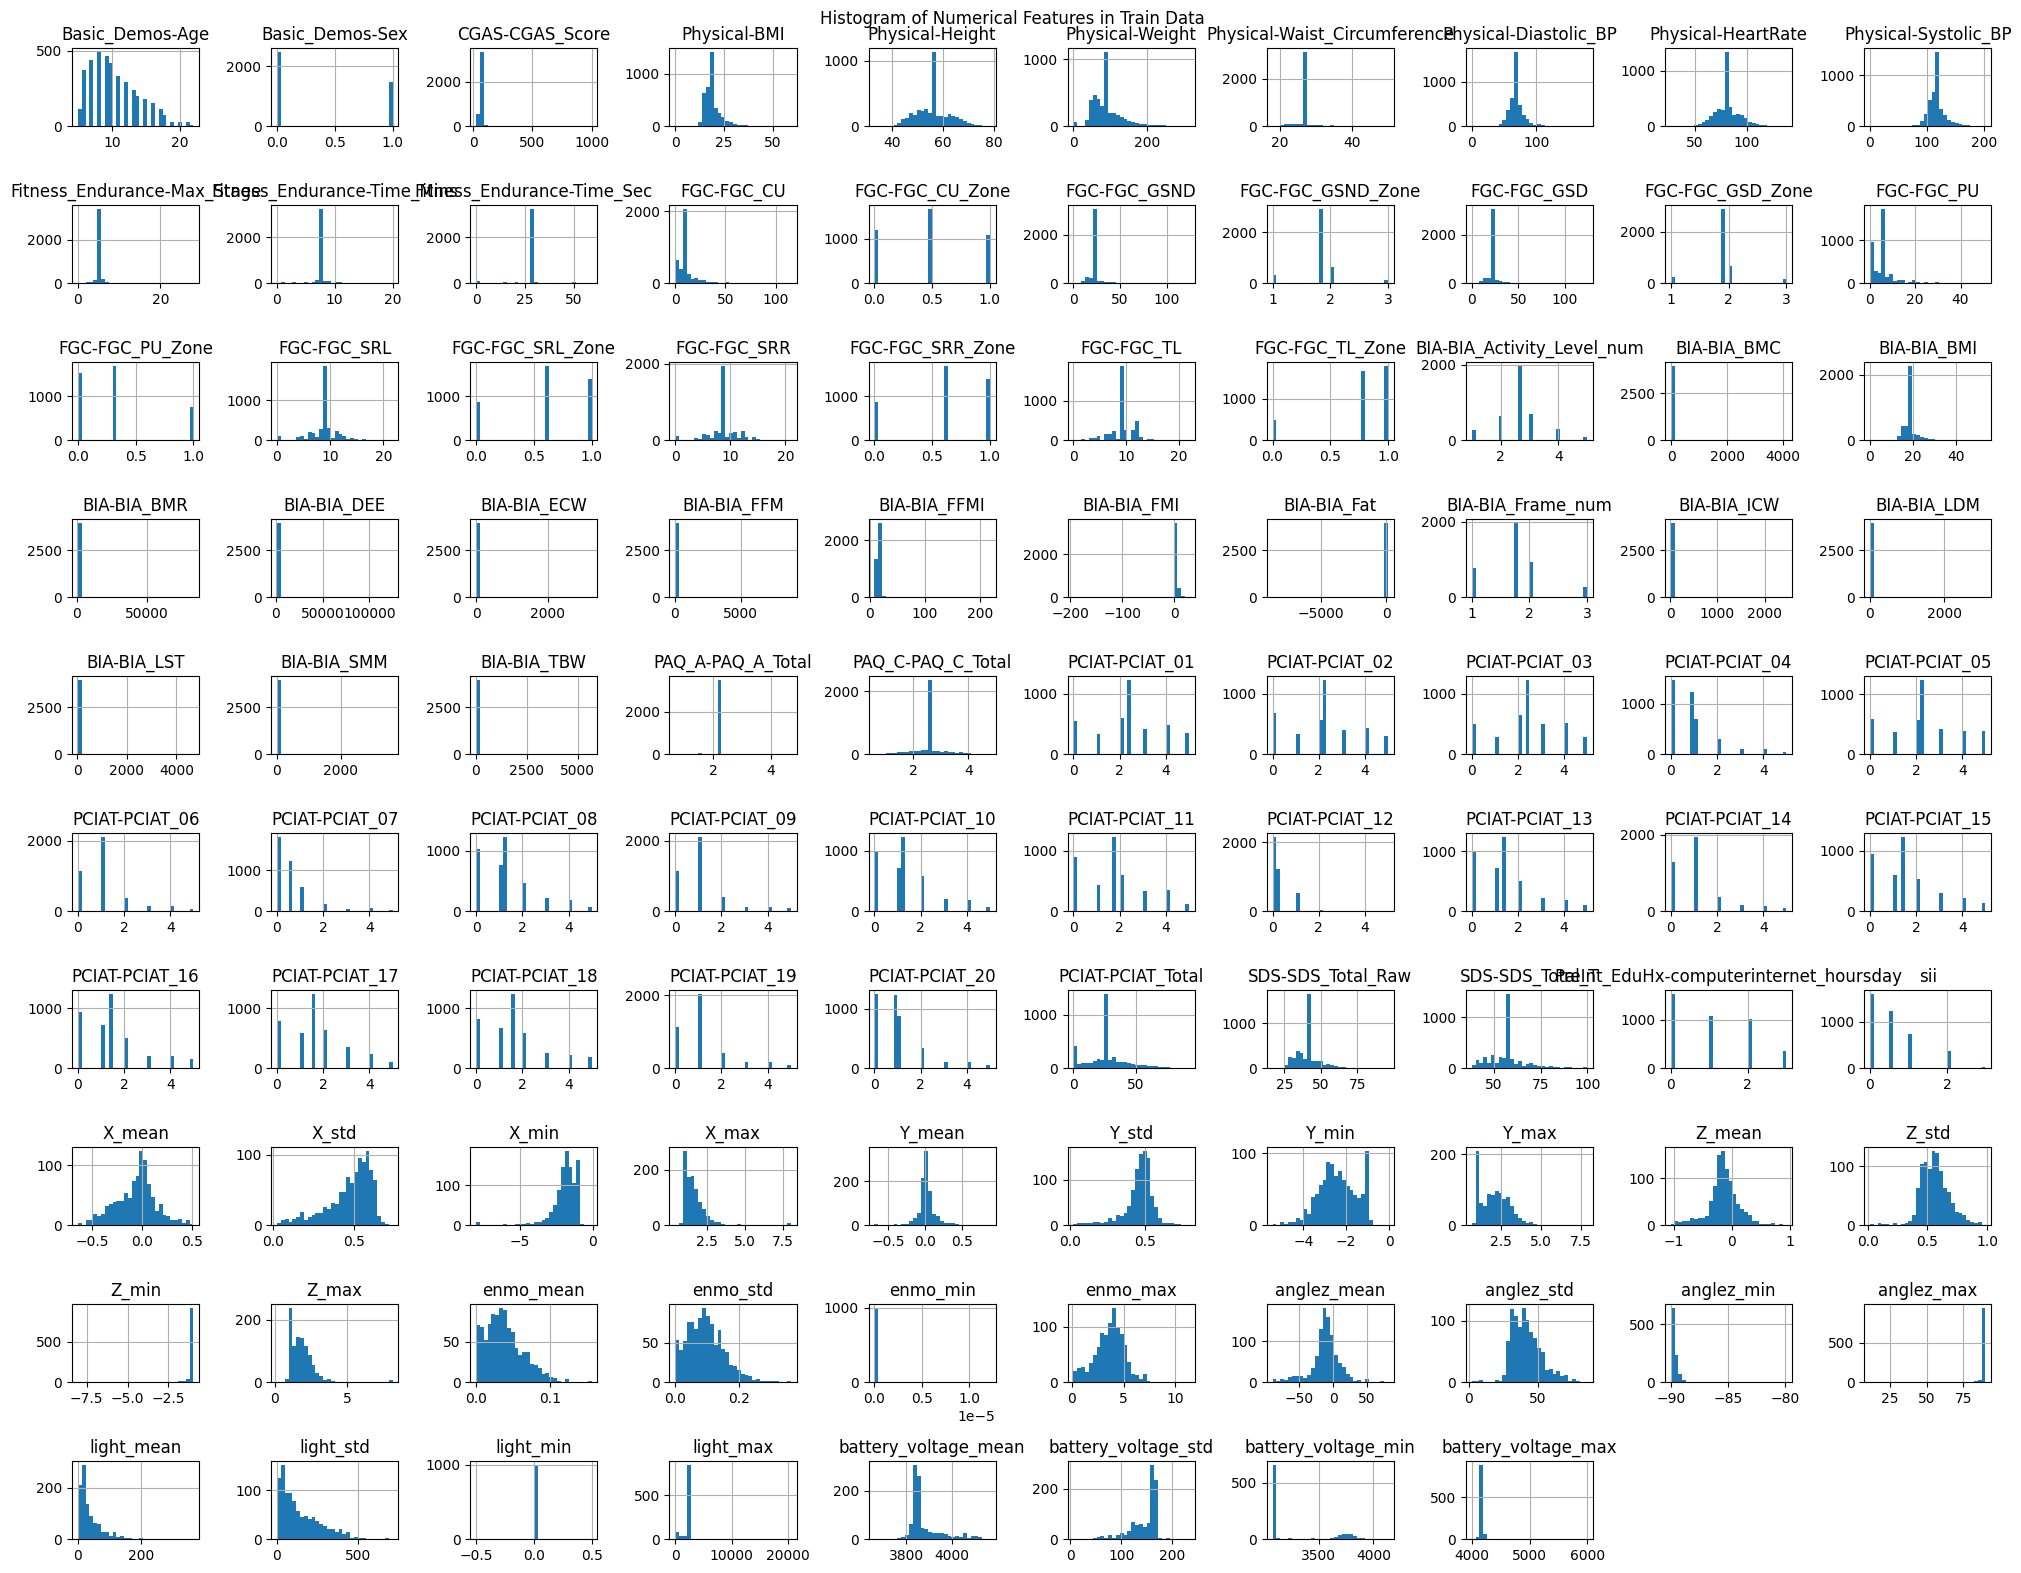

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograms for numerical features
merged_train_data.hist(figsize=(20, 16), bins=30)
plt.suptitle('Histogram of Numerical Features in Train Data')
plt.tight_layout()
plt.show()


4. Correlation Analysis

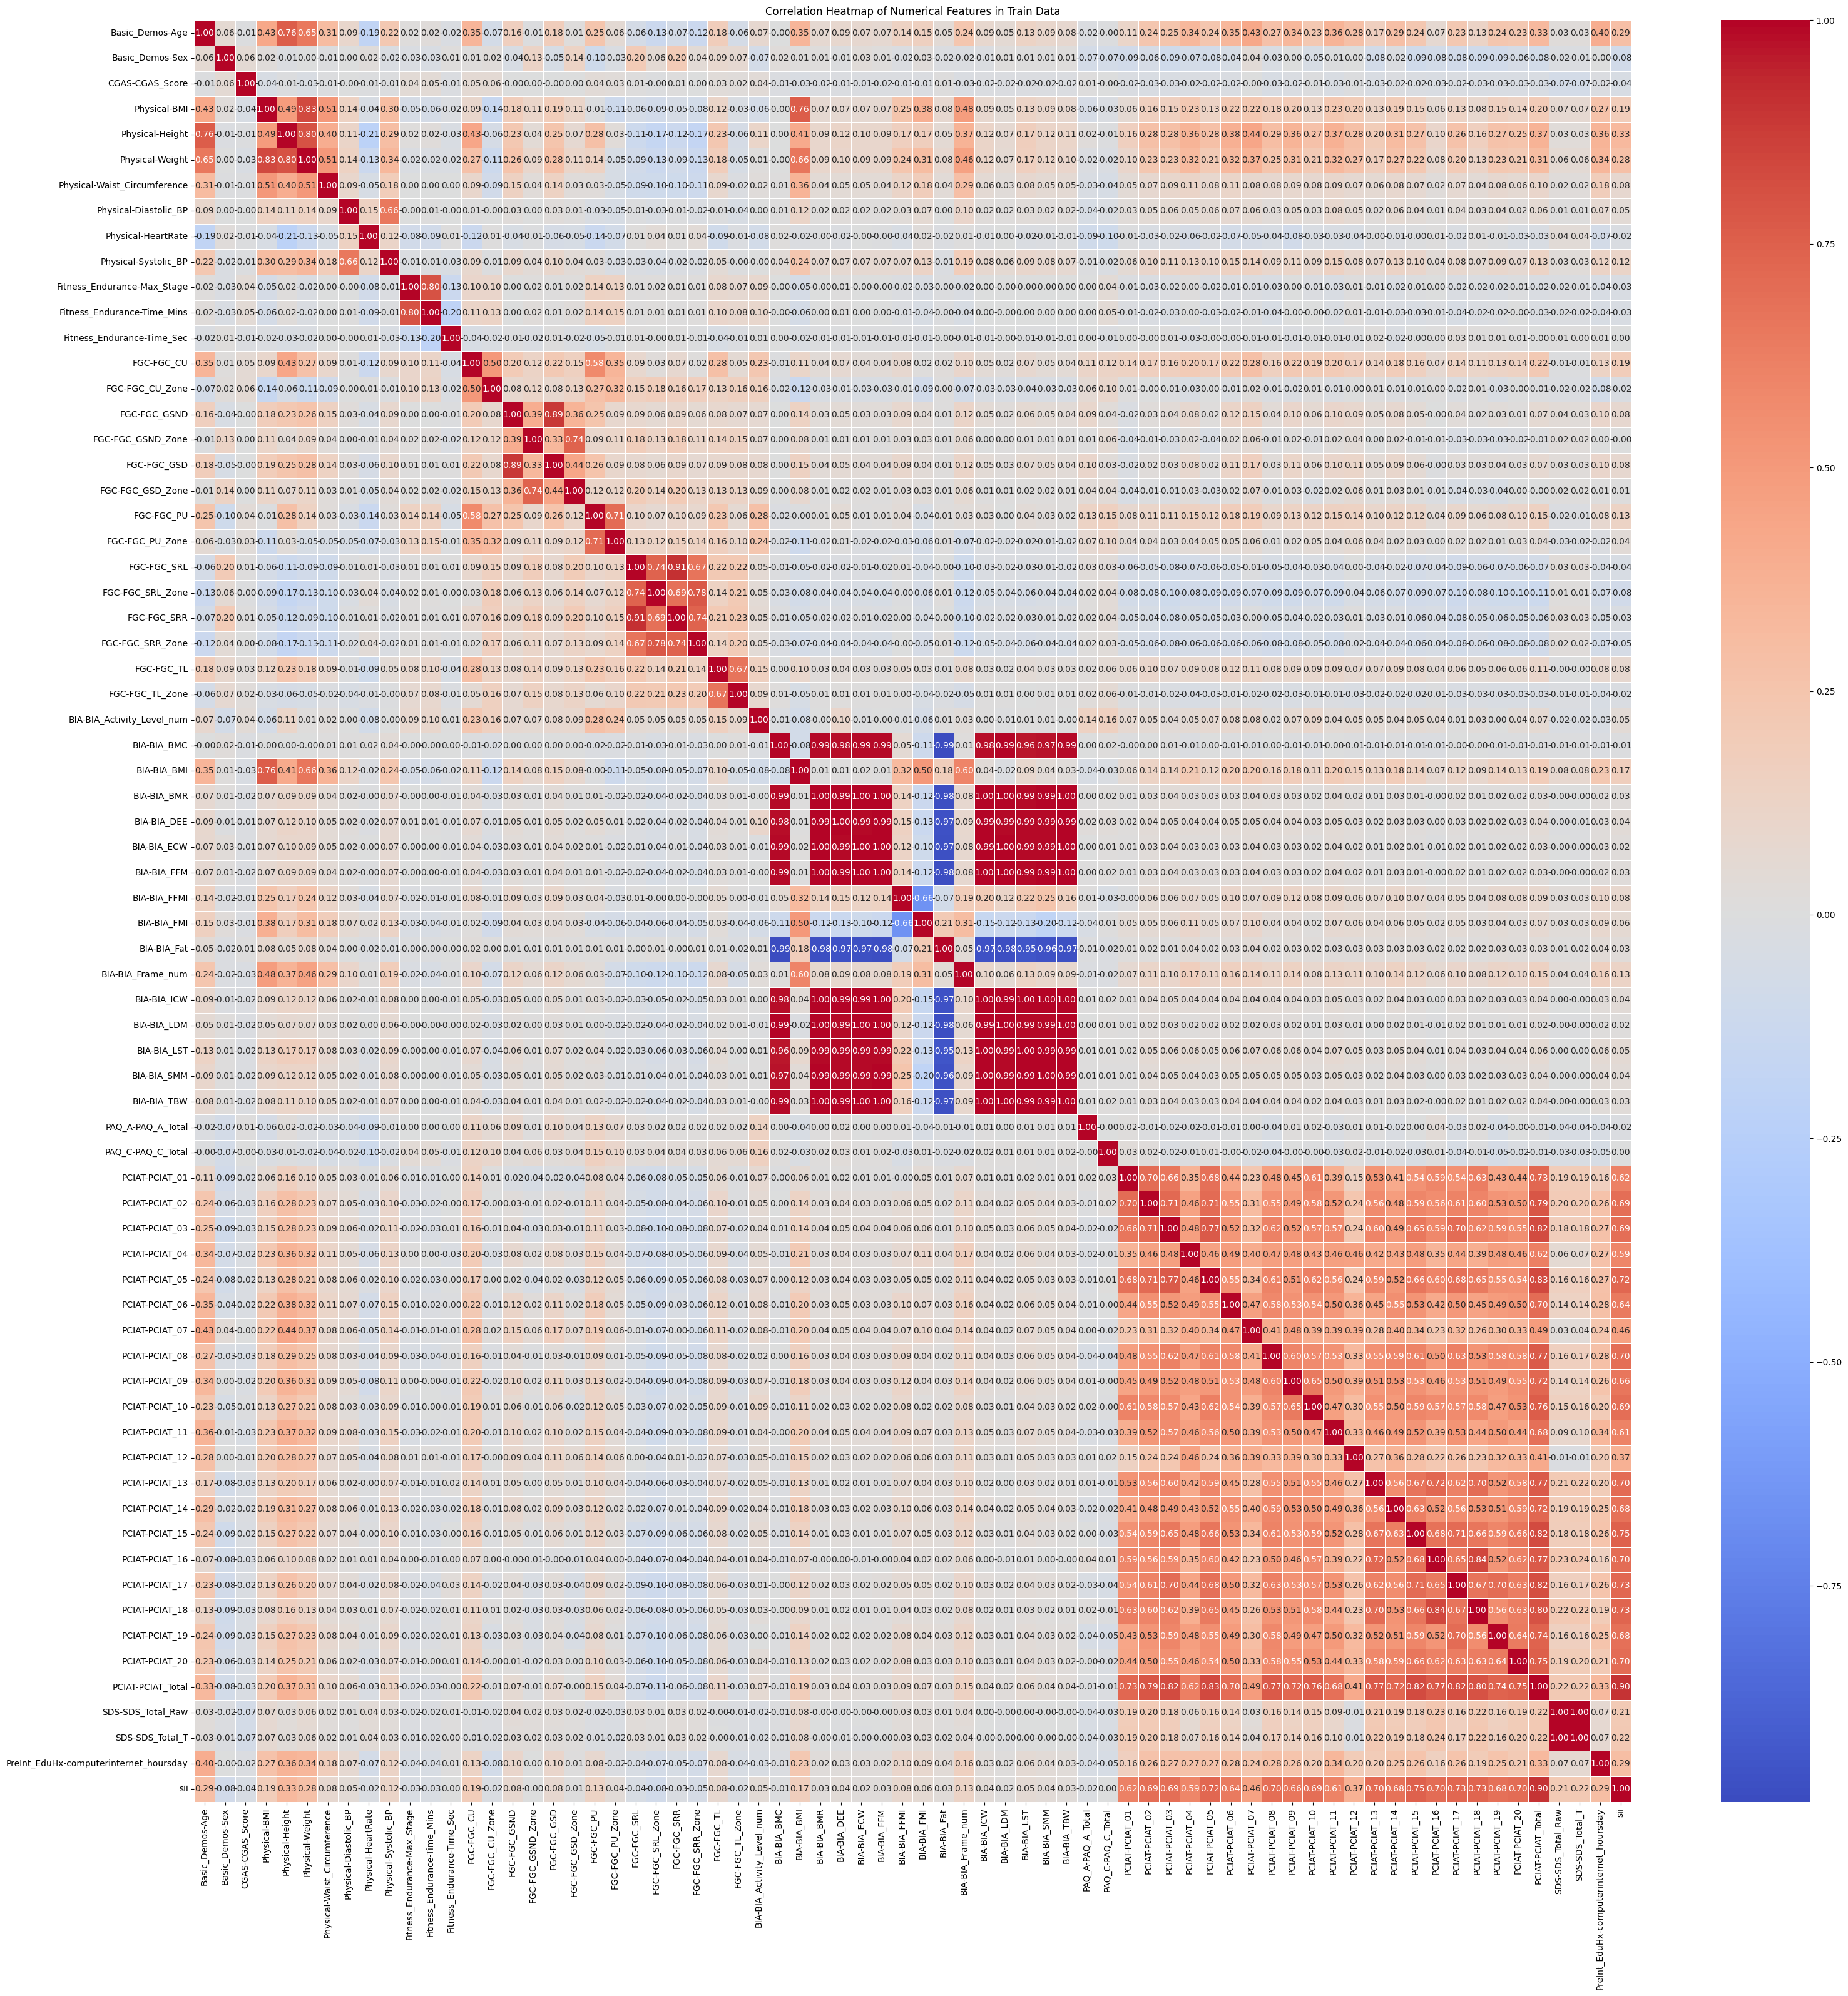

In [16]:
# Select only numerical columns for correlation matrix
numerical_columns = merged_train_data.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr = numerical_columns.corr()

# Heatmap of correlation matrix
plt.figure(figsize=(32, 32))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features in Train Data')
plt.tight_layout()
plt.show()


5. Data Distribution (Categorical Features)

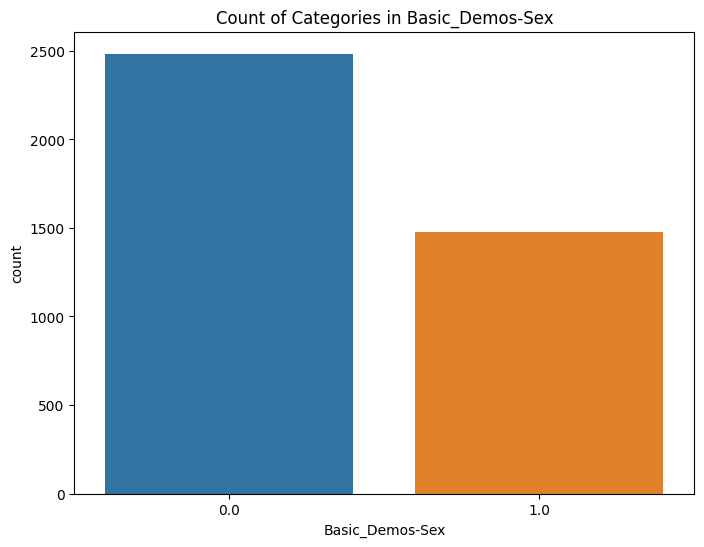

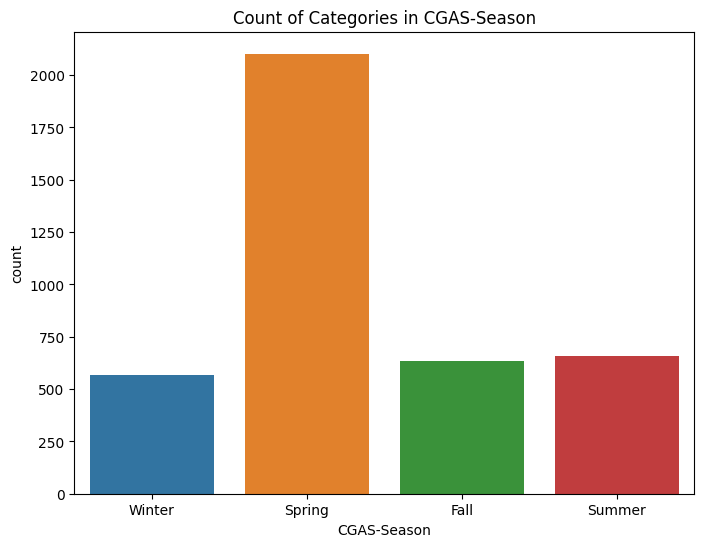

In [17]:
# Plot categorical features (example for 'Basic_Demos-Sex')
plt.figure(figsize=(8, 6))
sns.countplot(x='Basic_Demos-Sex', data=merged_train_data)
plt.title('Count of Categories in Basic_Demos-Sex')
plt.show()

# Example for 'CGAS-Season'
plt.figure(figsize=(8, 6))
sns.countplot(x='CGAS-Season', data=merged_train_data)
plt.title('Count of Categories in CGAS-Season')
plt.show()


6. Outliers Detection

   
Identify potential outliers using boxplots.

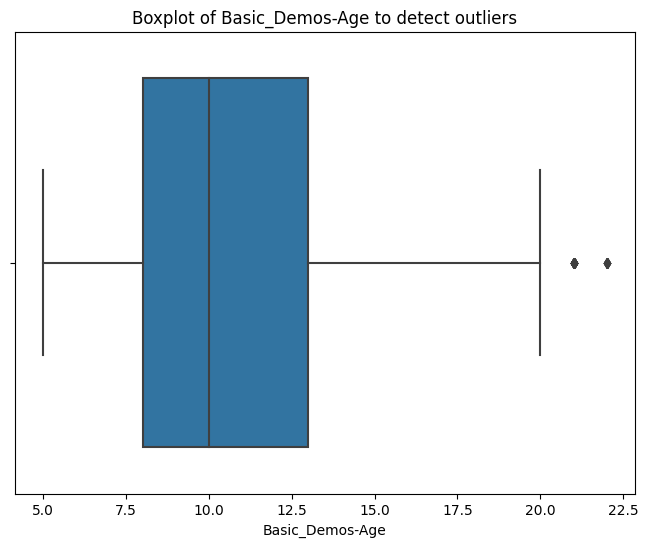

In [18]:
# Boxplot to detect outliers in 'Basic_Demos-Age'
plt.figure(figsize=(8, 6))
sns.boxplot(x=merged_train_data['Basic_Demos-Age'])
plt.title('Boxplot of Basic_Demos-Age to detect outliers')
plt.show()


7. Target Variable Analysis (sii)
   
Analyze the distribution of the target variable (sii).

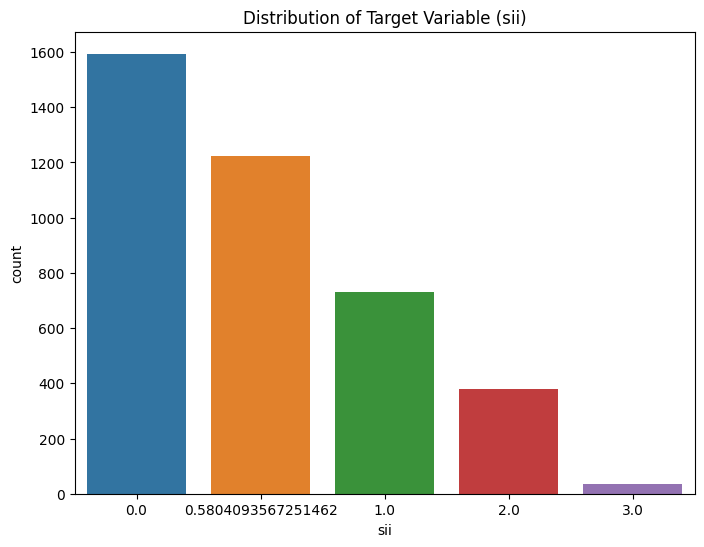

sii
0.000000    1594
0.580409    1224
1.000000     730
2.000000     378
3.000000      34
Name: count, dtype: int64


In [19]:
# Count plot for target variable 'sii'
plt.figure(figsize=(8, 6))
sns.countplot(x='sii', data=merged_train_data)
plt.title('Distribution of Target Variable (sii)')
plt.show()

# Analyze the target variable distribution (e.g., 'sii' as categorical)
print(merged_train_data['sii'].value_counts())


8. Check for Duplicates

Check if there are any duplicate entries in the data.

In [20]:
# Check for duplicate rows
print("Number of duplicate rows in train data:", merged_train_data.duplicated().sum())
print("Number of duplicate rows in test data:", merged_test_data.duplicated().sum())


Number of duplicate rows in train data: 0
Number of duplicate rows in test data: 0


9. Feature Engineering (if applicable)
Create new features or transform existing ones (e.g., extract day or month from timestamps).

In [21]:
# Z-score method for outlier detection
from scipy.stats import zscore

z_scores = zscore(merged_train_data[['Physical-BMI', 'Physical-Height', 'Physical-Weight']])
merged_train_data = merged_train_data[(z_scores < 3).all(axis=1)]


10. Visualizing Relationships
    
You can visualize relationships between key variables using scatter plots, box plots, etc.

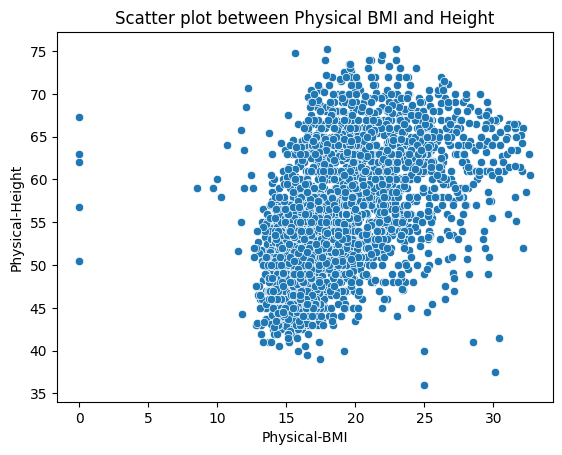

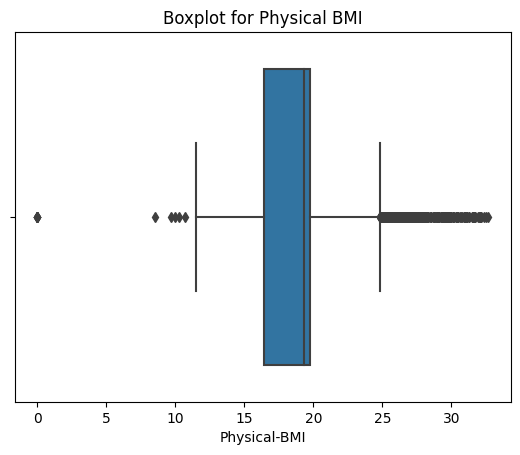

In [22]:
# Scatter plot between 'Physical-BMI' and 'Physical-Height'
sns.scatterplot(x='Physical-BMI', y='Physical-Height', data=merged_train_data)
plt.title('Scatter plot between Physical BMI and Height')
plt.show()

# Boxplot for 'Physical-BMI'
sns.boxplot(x='Physical-BMI', data=merged_train_data)
plt.title('Boxplot for Physical BMI')
plt.show()


10. Pairplot for Multivariate Analysis

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


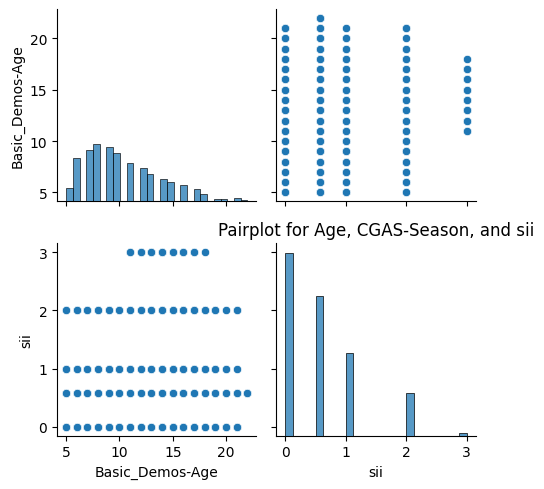

In [23]:
# Pairplot for a subset of features
sns.pairplot(merged_train_data[['Basic_Demos-Age', 'CGAS-Season', 'sii']])
plt.title('Pairplot for Age, CGAS-Season, and sii')
plt.tight_layout()
plt.show()


# Feature Engineering

Encoding Categorical Features: Use techniques like one-hot encoding or label encoding for categorical features in merged_train_data and merged_test_data.

In [24]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)
cat_features = ['Basic_Demos-Sex', 'CGAS-Season']  # Add relevant categorical columns
encoded_features = ohe.fit_transform(merged_train_data[cat_features])


/opt/conda/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


Scaling Numerical Features: Apply standard scaling (or MinMax scaling) to numerical features for consistent input magnitudes, especially if you plan to use neural networks or distance-based models.

In [25]:
scaler = StandardScaler()
numerical_cols = merged_train_data.select_dtypes(include=['float64', 'int64']).columns
merged_train_data[numerical_cols] = scaler.fit_transform(merged_train_data[numerical_cols])

# Categorical Features  

In [26]:
# One-hot encode categorical variables
categorical_cols = train_data.select_dtypes(include=['object']).columns
encoder = OneHotEncoder(sparse=False, handle_unknown='ignore')

encoded_train = pd.DataFrame(encoder.fit_transform(train_data[categorical_cols]))
encoded_test = pd.DataFrame(encoder.transform(test_data[categorical_cols]))

# Add encoded columns to train/test data
train_data = pd.concat([train_data.drop(columns=categorical_cols), encoded_train], axis=1)
test_data = pd.concat([test_data.drop(columns=categorical_cols), encoded_test], axis=1)

print("After Encoding:")
print(train_data.head())


After Encoding:
   Basic_Demos-Age  Basic_Demos-Sex  CGAS-CGAS_Score  Physical-BMI  \
0              5.0              0.0        51.000000     16.877316   
1              9.0              0.0        65.454771     14.035590   
2             10.0              1.0        71.000000     16.648696   
3              9.0              0.0        71.000000     18.292347   
4             18.0              1.0        65.454771     19.331929   

   Physical-Height  Physical-Weight  Physical-Waist_Circumference  \
0        46.000000        50.800000                     27.278508   
1        48.000000        46.000000                     22.000000   
2        56.500000        75.600000                     27.278508   
3        56.000000        81.600000                     27.278508   
4        55.946713        89.038615                     27.278508   

   Physical-Diastolic_BP  Physical-HeartRate  Physical-Systolic_BP  ...  3994  \
0              69.648951           81.597236            116.983074 

/opt/conda/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


# Time-Series Features

In [27]:
# Example: Rolling statistics for time-series features
def generate_time_series_features(data):
    for col in ['X', 'Y', 'Z', 'enmo', 'anglez']:
        data[f'{col}_mean'] = data[col].mean()
        data[f'{col}_std'] = data[col].std()
        data[f'{col}_rolling_mean'] = data[col].rolling(window=5).mean()
    return data

# Model Preparation

In [28]:
# Drop unnecessary columns (adjust as needed)
X = train_data.drop(columns=['sii'])

# Target variable
y = train_data['sii']

# Perform stratified train-validation split
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)


In [29]:
# Identify categorical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns

# One-hot encode categorical variables
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse=False, handle_unknown='ignore')

# Fit encoder on training data
encoder.fit(X_train[categorical_cols])

# Transform training and validation data
X_train_encoded = encoder.transform(X_train[categorical_cols])
X_val_encoded = encoder.transform(X_val[categorical_cols])

# Convert encoded features to DataFrame
encoded_cols = encoder.get_feature_names_out(categorical_cols)
X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoded_cols, index=X_train.index)
X_val_encoded_df = pd.DataFrame(X_val_encoded, columns=encoded_cols, index=X_val.index)

# Drop original categorical columns and concatenate encoded columns
X_train = X_train.drop(columns=categorical_cols).join(X_train_encoded_df)
X_val = X_val.drop(columns=categorical_cols).join(X_val_encoded_df)


/opt/conda/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [30]:
# Separate features and target
X = train_data.drop(columns=['sii', 'id'], errors='ignore')
y = train_data['sii']
test_features = test_data.drop(columns=['sii', 'id'], errors='ignore')

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Ensure column names are strings
X.columns = X.columns.astype(str)
test_features.columns = test_features.columns.astype(str)

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Ensure column names are consistent across training and validation sets
X_train.columns = X_train.columns.astype(str)
X_val.columns = X_val.columns.astype(str)

# Align test_features to match X_train's columns
test_features = test_features[X_train.columns]

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
test_data_scaled = scaler.transform(test_features)


In [32]:
print(X.shape)
print(pseudo_train.shape)


(3960, 4073)
(2736, 72)


In [33]:
columnas_tt = pseudo_train.columns.intersection(test_data.columns)

# Check if 'id' exists before dropping
if 'id' in columnas_tt:
    columnas_tt = columnas_tt.drop('id')  # Exclude 'id' from selected columns

X = pseudo_train.loc[:, columnas_tt]
y = pseudo_train.loc[X.index, 'sii']

# Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1111)


# Random Forest Baseline

In [34]:
model = RandomForestClassifier(random_state=1111)

In [35]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.8)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [36]:
# Assuming you have your training data X_train and y_train
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest Classifier
model = RandomForestClassifier()

# Fit the model with the training data
model.fit(X_train, y_train)

# Now you can generate predictions on the test set
predictions = model.predict(X_test)

In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

# Aplicaremos PCA para reducir la dimensionalidad
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_norm)
X_test_pca = pca.transform(X_test_norm)

In [38]:
print(y_train[:10])  # Display a sample of y_train
print(y_train.dtype)  # Check the data type

1113    0.0
2989    1.0
892     0.0
3940    0.0
1785    0.0
3734    0.0
1222    0.0
2315    1.0
1210    2.0
2654    2.0
Name: sii, dtype: float64
float64


In [39]:
import numpy as np

# Example: Categorize continuous values into bins
bins = [0, 50, 100, 150]  # Define bins
labels = ['low', 'medium', 'high']  # Define class labels
y_train_binned = pd.cut(y_train, bins=bins, labels=labels)

print(y_train_binned[:10])  # Verify the transformation


1113    NaN
2989    low
892     NaN
3940    NaN
1785    NaN
3734    NaN
1222    NaN
2315    low
1210    low
2654    low
Name: sii, dtype: category
Categories (3, object): ['low' < 'medium' < 'high']


In [40]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=1111,
                           max_depth=8, min_samples_split=10,
                           min_samples_leaf=4)
rf.fit(X_train_pca, y_train)

RandomForestRegressor(max_depth=8, min_samples_leaf=4, min_samples_split=10,
                      random_state=1111)

In [41]:
from sklearn.metrics import r2_score, mean_squared_error, confusion_matrix
import numpy as np
import pandas as pd
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import cohen_kappa_score

In [42]:
# Predictions
y_pred = rf.predict(X_test_pca)

# R² Score
r2_rf = r2_score(y_test, y_pred)
print(f"R² Score: {r2_rf:.4f}")

# Mean Squared Error
mse_rf = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse_rf:.4f}")

R² Score: 0.9551
Mean Squared Error: 0.0275


In [43]:
# Define bins for discretization
bins = [0, 50, 100, 150]  # Customize bins based on your data
labels = ['low', 'medium', 'high']  # Customize based on bins

# Initialize KBinsDiscretizer
discretizer = KBinsDiscretizer(n_bins=len(bins) - 1, encode='ordinal', strategy='uniform')

# Ensure y_test and y_pred are NumPy arrays and discretize
y_test_binned = discretizer.fit_transform(y_test.values.reshape(-1, 1)).flatten()
y_pred_binned = discretizer.transform(y_pred.reshape(-1, 1)).flatten()


In [44]:
# Confusion Matrix
conf_matrix = confusion_matrix(y_test_binned, y_pred_binned)
print("Confusion Matrix:")
print(conf_matrix)

# Quadratic Weighted Kappa
qwk_rf = cohen_kappa_score(y_test_binned, y_pred_binned, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK) Score: {qwk_rf:.4f}")


Confusion Matrix:
[[465   0   0]
 [155  68   1]
 [  0  60  72]]
Quadratic Weighted Kappa (QWK) Score: 0.7448


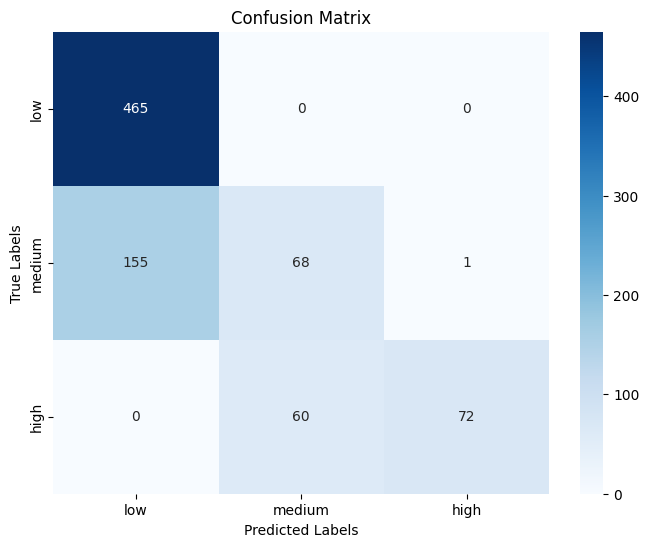

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


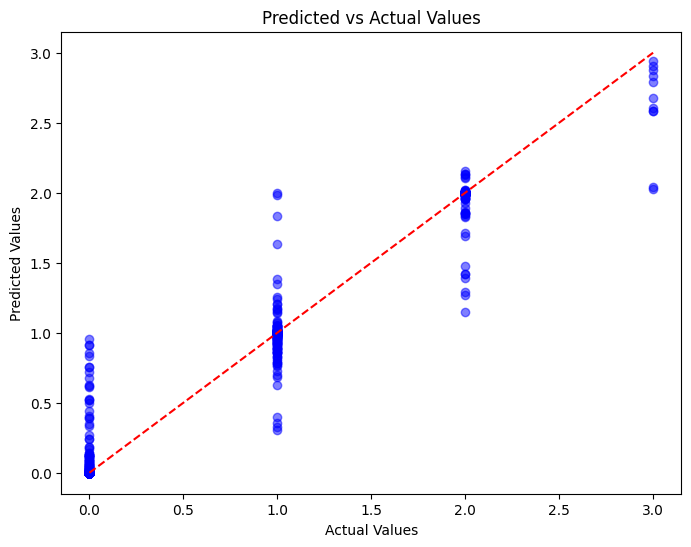

In [46]:
# Plotting Predicted vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Ideal line
plt.title("Predicted vs Actual Values")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.show()


# Cumulative Gains Chart (Lift Chart):

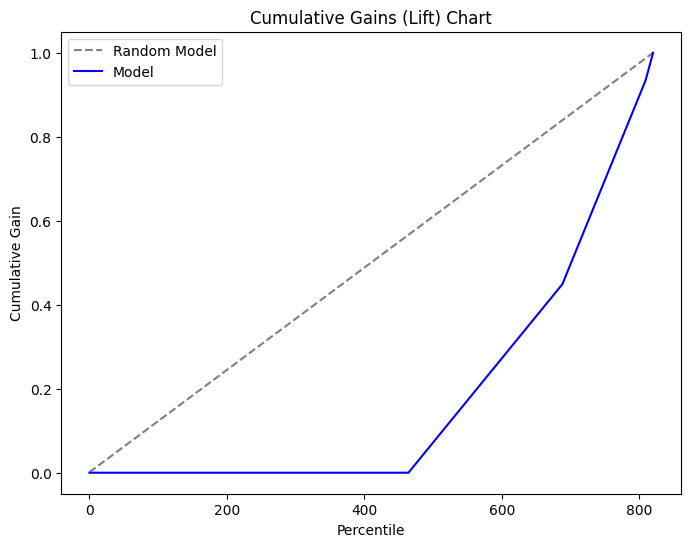

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Cumulative Gains (Lift) Chart
# Calculate True Positive Rate (Recall) for each bin
sorted_true = np.sort(y_test)
sorted_pred = np.sort(y_pred)

# Calculate cumulative true positive rate for the sorted predictions
cumulative_true = np.cumsum(sorted_true) / np.sum(sorted_true)
cumulative_random = np.arange(1, len(sorted_true) + 1) / len(sorted_true)

plt.figure(figsize=(8, 6))
plt.plot(cumulative_random, label="Random Model", linestyle='--', color='gray')
plt.plot(cumulative_true, label="Model", color='blue')
plt.title("Cumulative Gains (Lift) Chart")
plt.xlabel("Percentile")
plt.ylabel("Cumulative Gain")
plt.legend()
plt.show()


# Residuals Histogram:

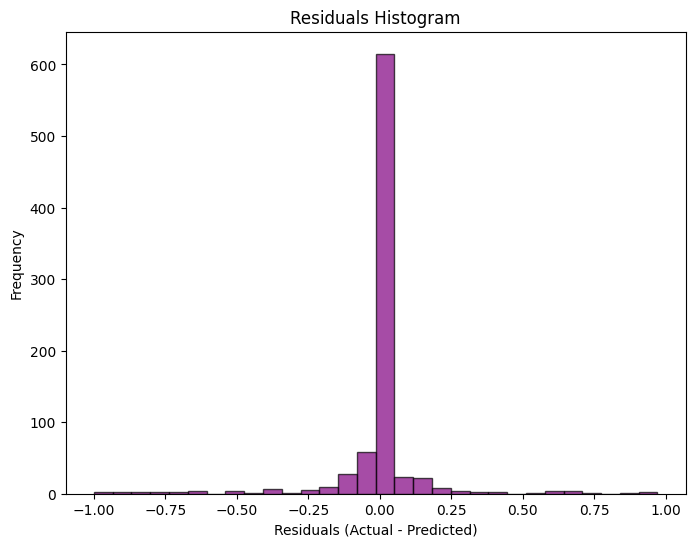

In [48]:
# Residuals calculation
residuals = y_test - y_pred

# Plotting residuals as a histogram
plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, edgecolor='black', color='purple', alpha=0.7)
plt.title("Residuals Histogram")
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()


# Precision-Recall Curve (for each class):

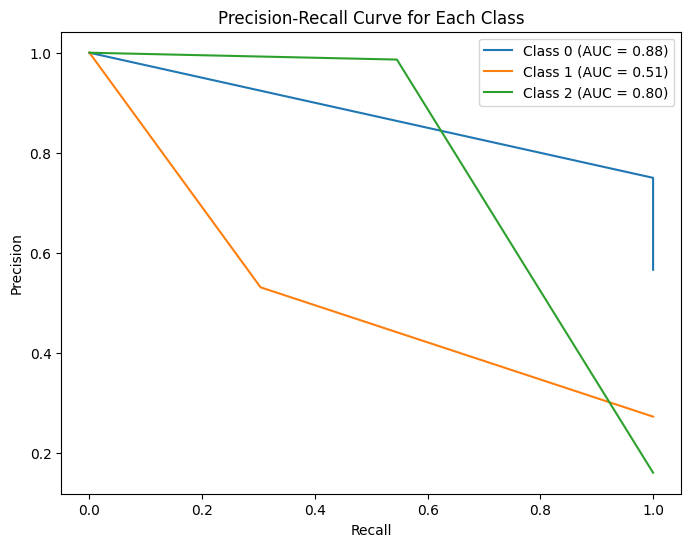

In [49]:
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt

# Binarize the labels for multiclass problem
lb = LabelBinarizer()
y_test_binarized = lb.fit_transform(y_test_binned)
y_pred_binarized = lb.transform(y_pred_binned)

# Plot precision-recall curve for each class and print AUC
plt.figure(figsize=(8, 6))
for i in range(y_test_binarized.shape[1]):
    precision, recall, _ = precision_recall_curve(y_test_binarized[:, i], y_pred_binarized[:, i])
    auc_score = auc(recall, precision)  # Calculate AUC for each class
    plt.plot(recall, precision, label=f'Class {i} (AUC = {auc_score:.2f})')

plt.title("Precision-Recall Curve for Each Class")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()


# XGBoost

In [50]:
import xgboost as xgb
from sklearn.metrics import r2_score, mean_squared_error, confusion_matrix
from sklearn.preprocessing import KBinsDiscretizer
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score

In [51]:
# Initialize the XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=100,       # Number of trees
    max_depth=8,            # Maximum tree depth
    learning_rate=0.1,      # Step size shrinkage
    min_child_weight=10,    # Minimum sum of instance weight
    subsample=0.8,          # Subsample ratio of the training instance
    colsample_bytree=0.8,   # Subsample ratio of columns when constructing each tree
    random_state=1111       # For reproducibility
)

# Fit the model to training data
xgb_model.fit(X_train_pca, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=8, max_leaves=None,
             min_child_weight=10, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=1111, ...)

In [52]:
# Make predictions on the test data
y_pred = xgb_model.predict(X_test_pca)

# R² Score
r2_xgb = r2_score(y_test, y_pred)
print(f"R² Score: {r2_xgb:.4f}")

# Mean Squared Error
mse_xgb = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse_xgb:.4f}")

R² Score: 0.9671
Mean Squared Error: 0.0202


In [53]:
# Define bins for discretization
bins = [0, 50, 100, 150]  # Customize bins based on your data
labels = ['low', 'medium', 'high']  # Customize based on bins

# Discretize actual and predicted values
discretizer = KBinsDiscretizer(n_bins=len(bins) - 1, encode='ordinal', strategy='uniform')

y_test_binned = discretizer.fit_transform(y_test.values.reshape(-1, 1)).flatten()
y_pred_binned = discretizer.transform(y_pred.reshape(-1, 1)).flatten()


In [54]:
# Confusion Matrix
conf_matrix = confusion_matrix(y_test_binned, y_pred_binned)
print("Confusion Matrix:")
print(conf_matrix)

# Quadratic Weighted Kappa (QWK) Score
qwk_xgb = cohen_kappa_score(y_test_binned, y_pred_binned, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK) Score: {qwk_xgb:.4f}")


Confusion Matrix:
[[465   0   0]
 [123 100   1]
 [  0  69  63]]
Quadratic Weighted Kappa (QWK) Score: 0.7658


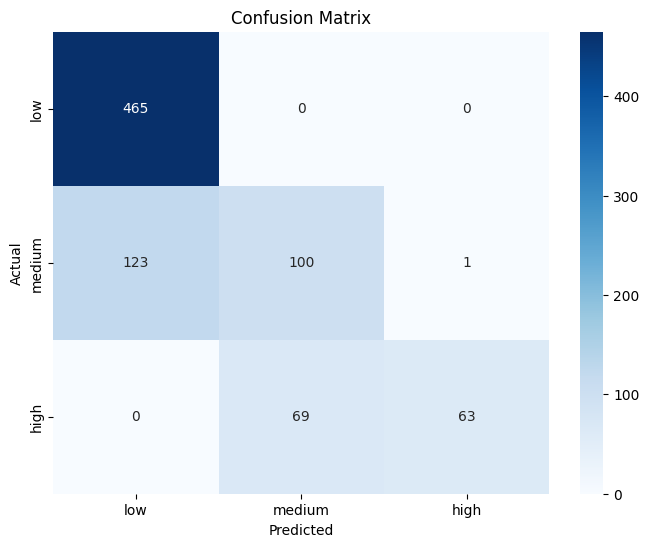

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [56]:
xgb_model.fit(X_train_pca, y_train)
print("Model fitting complete.")

Model fitting complete.


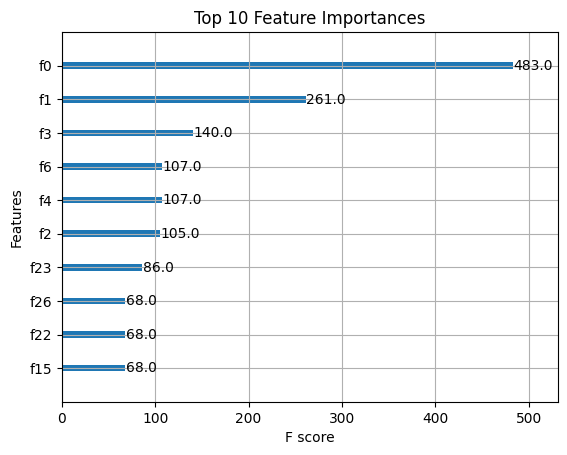

In [57]:
xgb.plot_importance(xgb_model, importance_type='weight', max_num_features=10)
plt.title("Top 10 Feature Importances")
plt.show()

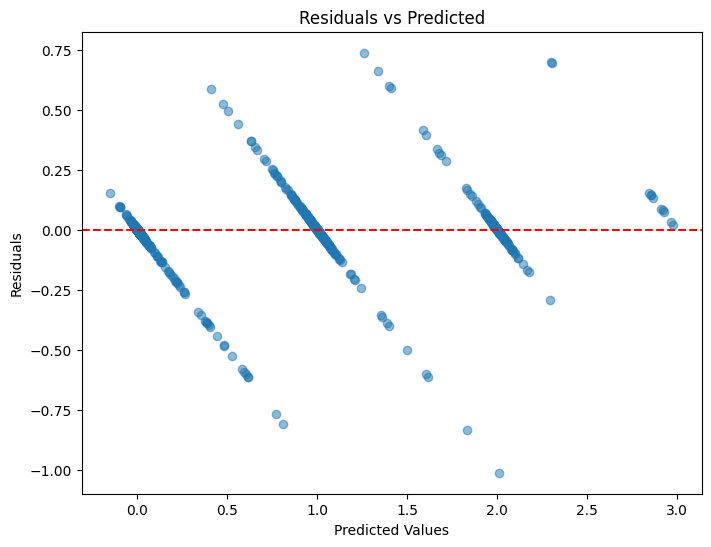

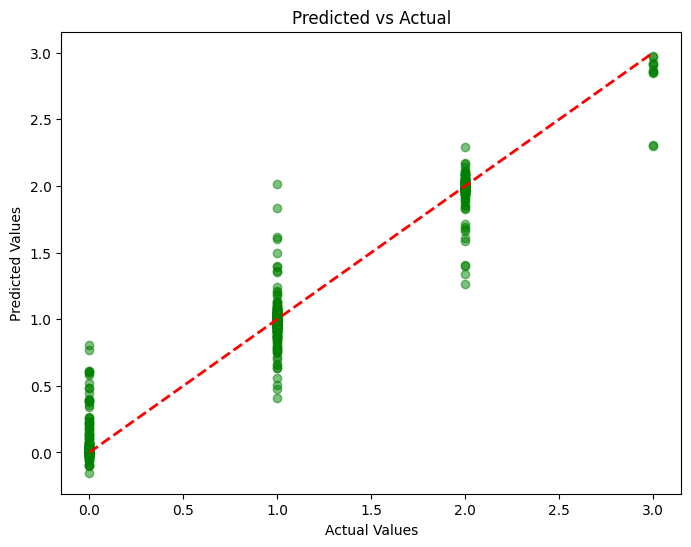

In [58]:
# Residuals Plot
residuals = y_test - y_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.title("Residuals vs Predicted")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()

# Predicted vs Actual Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.title("Predicted vs Actual")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.show()

# Cumulative Gains Chart (Lift Chart)

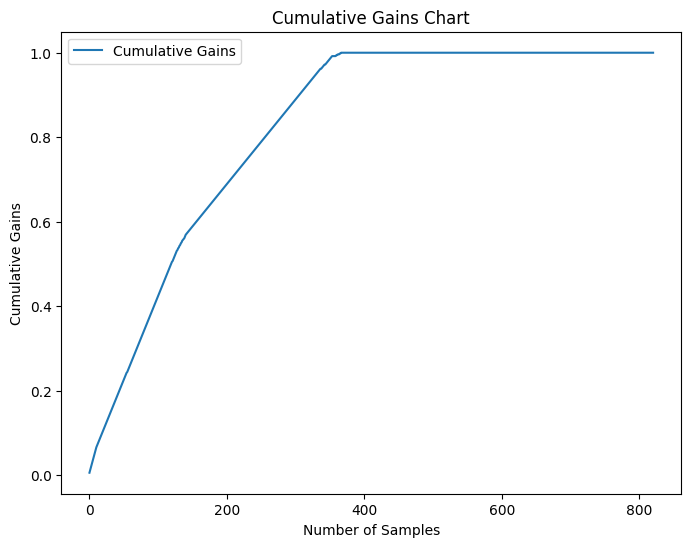

In [59]:
from sklearn.metrics import roc_curve

# Calculate predicted probabilities
y_prob = xgb_model.predict(X_test_pca)

# Sort actual values by predicted probabilities
sorted_indices = np.argsort(y_prob)[::-1]
y_sorted = y_test.iloc[sorted_indices]

# Calculate cumulative gains
cum_gains = np.cumsum(y_sorted) / np.sum(y_sorted)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(np.arange(len(cum_gains)), cum_gains, label='Cumulative Gains')
plt.title("Cumulative Gains Chart")
plt.xlabel("Number of Samples")
plt.ylabel("Cumulative Gains")
plt.legend()
plt.show()


# Residuals Histogram

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


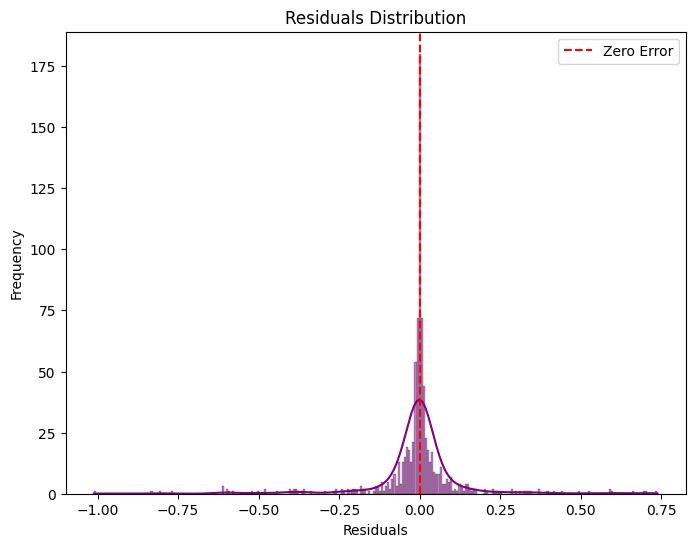

In [60]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True, color='purple')
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.axvline(0, color='red', linestyle='--', label='Zero Error')
plt.legend()
plt.show()


# Precision-Recall Curve

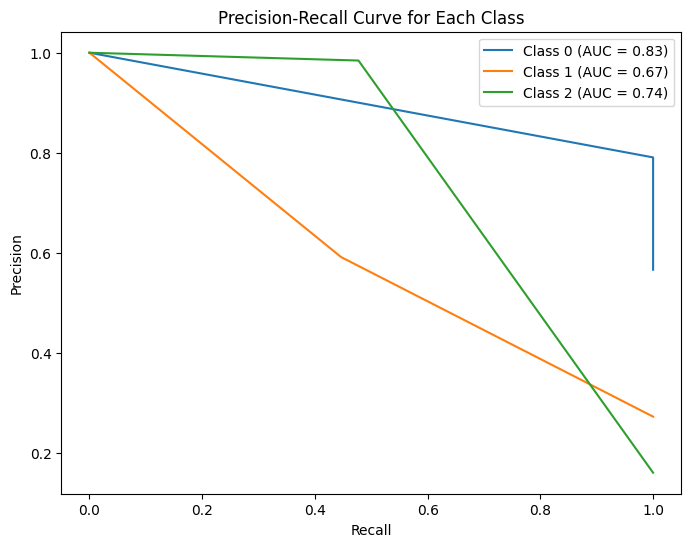

In [61]:
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import precision_recall_curve, roc_auc_score
import matplotlib.pyplot as plt

# Binarize the labels for multiclass problem
lb = LabelBinarizer()
y_test_binarized = lb.fit_transform(y_test_binned)
y_pred_binarized = lb.transform(y_pred_binned)

# Plot precision-recall curve for each class
plt.figure(figsize=(8, 6))
for i in range(y_test_binarized.shape[1]):
    precision, recall, _ = precision_recall_curve(y_test_binarized[:, i], y_pred_binarized[:, i])
    auc_score = roc_auc_score(y_test_binarized[:, i], y_pred_binarized[:, i])
    plt.plot(recall, precision, label=f'Class {i} (AUC = {auc_score:.2f})')

plt.title("Precision-Recall Curve for Each Class")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()


# comparison

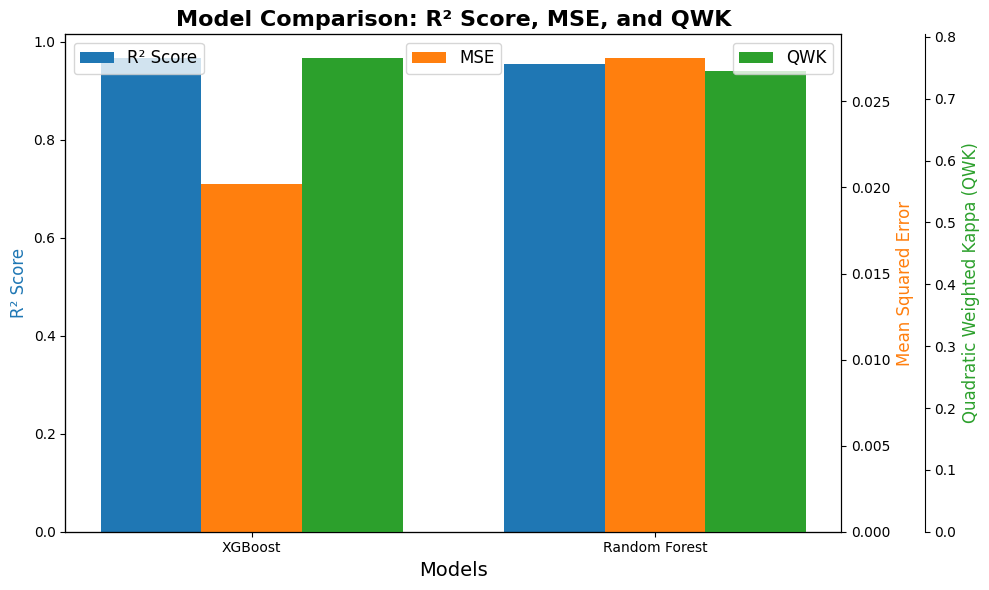

In [62]:
import matplotlib.pyplot as plt
import numpy as np

# R² Scores for both models
r2_scores = [r2_xgb, r2_rf]

# Mean Squared Errors for both models
mse_scores = [mse_xgb, mse_rf]

# Quadratic Weighted Kappa for both models
qwk_scores = [qwk_xgb, qwk_rf]

# Labels for the models
models = ['XGBoost', 'Random Forest']

# Set the position for the bars
x = np.arange(len(models))

# Width of the bars
width = 0.25

# Create a figure and axis for the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot R² Score as bars with a bright blue color
bar1 = ax1.bar(x - width, r2_scores, width, label='R² Score', color='#1f77b4')  # Dark blue

# Plot MSE as bars with a vibrant orange color (on a secondary y-axis)
ax2 = ax1.twinx()
bar2 = ax2.bar(x, mse_scores, width, label='MSE', color='#ff7f0e')  # Vibrant orange

# Plot QWK as bars with a fresh green color (on a third y-axis)
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('outward', 60))  # To avoid overlap with ax2
bar3 = ax3.bar(x + width, qwk_scores, width, label='QWK', color='#2ca02c')  # Fresh green

# Add labels and titles
ax1.set_xlabel('Models', fontsize=14)
ax1.set_ylabel('R² Score', color='#1f77b4', fontsize=12)
ax2.set_ylabel('Mean Squared Error', color='#ff7f0e', fontsize=12)
ax3.set_ylabel('Quadratic Weighted Kappa (QWK)', color='#2ca02c', fontsize=12)

ax1.set_title('Model Comparison: R² Score, MSE, and QWK', fontsize=16, weight='bold')

# Add a legend
ax1.legend(loc='upper left', fontsize=12)
ax2.legend(loc='upper center', fontsize=12)
ax3.legend(loc='upper right', fontsize=12)

# Show the plot
plt.xticks(x, models, fontsize=12)
plt.tight_layout()
plt.show()


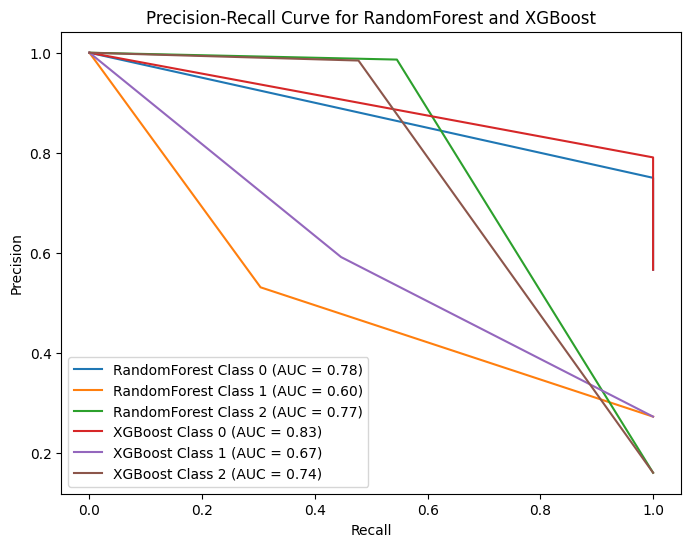

In [63]:
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, roc_auc_score, r2_score, mean_squared_error, confusion_matrix
from sklearn.preprocessing import KBinsDiscretizer, LabelBinarizer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Predictions for both models
y_pred_rf = rf.predict(X_test_pca)
y_pred_xgb = xgb_model.predict(X_test_pca)

# Binning the predicted values for classification evaluation
bins = [0, 50, 100, 150]
labels = ['low', 'medium', 'high']

# Initialize KBinsDiscretizer
discretizer = KBinsDiscretizer(n_bins=len(bins) - 1, encode='ordinal', strategy='uniform')

y_test_binned = discretizer.fit_transform(y_test.values.reshape(-1, 1)).flatten()
y_pred_rf_binned = discretizer.transform(y_pred_rf.reshape(-1, 1)).flatten()
y_pred_xgb_binned = discretizer.transform(y_pred_xgb.reshape(-1, 1)).flatten()

# Precision-Recall Curve for RandomForest
lb = LabelBinarizer()
y_test_binarized = lb.fit_transform(y_test_binned)
y_pred_rf_binarized = lb.transform(y_pred_rf_binned)

plt.figure(figsize=(8, 6))
for i in range(y_test_binarized.shape[1]):
    precision_rf, recall_rf, _ = precision_recall_curve(y_test_binarized[:, i], y_pred_rf_binarized[:, i])
    auc_score_rf = roc_auc_score(y_test_binarized[:, i], y_pred_rf_binarized[:, i])
    plt.plot(recall_rf, precision_rf, label=f'RandomForest Class {i} (AUC = {auc_score_rf:.2f})')

# Precision-Recall Curve for XGBoost
y_pred_xgb_binarized = lb.transform(y_pred_xgb_binned)

for i in range(y_test_binarized.shape[1]):
    precision_xgb, recall_xgb, _ = precision_recall_curve(y_test_binarized[:, i], y_pred_xgb_binarized[:, i])
    auc_score_xgb = roc_auc_score(y_test_binarized[:, i], y_pred_xgb_binarized[:, i])
    plt.plot(recall_xgb, precision_xgb, label=f'XGBoost Class {i} (AUC = {auc_score_xgb:.2f})')

plt.title("Precision-Recall Curve for RandomForest and XGBoost")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()


Submission Preparation

In [64]:
test_data['id'] = test_data.index  # Creates a new 'id' column based on the row index

In [65]:
# Ensure predictions are aligned with the test data
aligned_predictions = predictions[:len(test_data)]  # Truncate predictions if needed

# Create the submission DataFrame
submission = pd.DataFrame({
    'id': test_data['id'],  # Now this should work
    'sii': aligned_predictions
})


# Save the submission file
submission.to_csv('submission.csv', index=False)
print("Submission file created: submission.csv")


Submission file created: submission.csv


In [66]:
# # If predictions were made for a larger dataset, filter them to match `test_data`
# predictions = predictions[:len(test_data)]  # Truncate or adjust as necessary

# # Ensure alignment before creating the submission file
# submission = pd.DataFrame({
#     'id': test_data['id'],  # Ensure this matches test_data
#     'sii': predictions      # Ensure this matches the adjusted predictions
# })

# # Save the submission file
# submission.to_csv('submission.csv', index=False)

# print("Submission file created: submission.csv")


# **Conclusion**

In an era where the internet plays an integral role in our lives, it is crucial to address the growing concern of problematic internet use among children and adolescents. This project demonstrates how physical activity and fitness data can serve as accessible and reliable indicators for identifying early signs of internet addiction. By leveraging machine learning models, we have shown that it is possible to predict problematic internet use, paving the way for timely interventions.

Our work emphasizes the importance of proactive measures to promote healthier digital habits and reduce the negative impacts of excessive screen time on mental and physical well-being. Beyond the scope of this study, these findings open doors to creating practical tools that parents, educators, and healthcare professionals can use to support children in navigating the digital landscape responsibly.

Ultimately, this project contributes to building a healthier and more balanced future for the next generation—one where technology is used as a tool for growth and connection rather than a source of dependency. Together, we can empower children and adolescents to lead healthier, more fulfilling lives in this ever-evolving digital world.